# What shapes Airbnb prices?

## Goal
<ol>
<li> Finding the answer to the question which variable most influence the rental price in three cities: Berlin, Munich and Prague </li>
<li> Understanding how OCI ADS library supports Data Science use cases </li>
<li> Understand regression analysis in machine learning </li>
</ol>

## Prereqs

Conda environment installed and activated.
Required libraries and version used in this notebook.
To read/write files to Object Storage, use ocifs:

<ol>
    <li> github.com/oracle/ocifs </li>
    <li> docs: https://docs.oracle.com/en-us/iaas/tools/ocifs-sdk/latest/unix-operations.html</li>
</ol>

## Source data
<ol>
<li> Berlin -> listings_berlin_11_2019.csv </li>
<li> Munuch -> listings_munich_11_2019.csv </li>
<li> Prague -> listings_prague_11_2019.csv </li>
</ol>

## 0. Required imports and displaying version used

In [97]:
!pip install oracle-ads==2.11.1

In [98]:
import pandas as pd # for data manipulation
import numpy as np  # fast n-dimensional arrays library
import statsmodels.formula.api as smf # for linear regresion
import seaborn as sns # for data visualization
import matplotlib.pyplot as plt # for data visualization
from sklearn import preprocessing # for preprocessing for LASSO algorithm
from sklearn.metrics import mean_squared_error # metric for comparing models
from sklearn import linear_model # for LASSO algorithm
from PIL import Image # for images manipulation
import ads # OCI ADS library
from ads.dataset.factory import DatasetFactory

In [99]:
print("Version of libraries used")
print("pandas: " + pd.__version__)
print("numpy: " + np.__version__)
import statsmodels as lib
print("statsmodels: " + lib.__version__)
del lib
print("sns: " + sns.__version__)
import matplotlib as lib
print("matplotlib.pyplot: " + lib.__version__)
del lib
import sklearn as lib
print("sklearn: " + lib.__version__)
del lib
import PIL as lib
print("PIL: " + lib.__version__)
del lib

Version of libraries used
pandas: 1.4.4
numpy: 1.23.3
statsmodels: 0.13.5
sns: 0.12.0
matplotlib.pyplot: 3.5.2
sklearn: 1.1.2
PIL: 9.2.0


In [100]:
from ads.common.auth import default_signer
import fsspec
from ocifs import OCIFileSystem

# Using resource principal auth method:
print(ads.__version__)
ads.set_auth(auth="resource_principal")

2.11.1


## I. Data Access

In [103]:
# object storage bucket + data 
bucket = "Airbnb"
namespace = "ocuocictrng20"

In [104]:
berlinsrcfile = "listings_berlin_11_2019.csv"
munichsrcfile = "listings_munich_11_2019.csv"
praquesrcfile = "listings_prague_11_2019.csv"

data_berlin = pd.read_csv(f"oci://{bucket}@{namespace}/{berlinsrcfile}",
                         storage_options=default_signer())
print(f"Source file for Berlin: {berlinsrcfile}")
print(f"size {data_berlin.shape}")

data_munich = pd.read_csv(f"oci://{bucket}@{namespace}/{munichsrcfile}",
                         storage_options=default_signer())
print(f"Source file for Munich: {munichsrcfile}")
print(f"size {data_munich.shape}")

data_praque = pd.read_csv(f"oci://{bucket}@{namespace}/{praquesrcfile}",
                         storage_options=default_signer())
print(f"Source file for Praque: {praquesrcfile}")
print(f"size {data_praque.shape}")

Source file for Berlin: listings_berlin_11_2019.csv
size (22552, 96)
Source file for Munich: listings_munich_11_2019.csv
size (11481, 106)
Source file for Praque: listings_prague_11_2019.csv
size (6782, 74)


ADS library provides a lot of additional features when dataframe is presented as ADSDataset.
<ol>
<li> Automatically detects feature types in dataset</li>
<li> Friendly function show_in_notebook allows quick and nice perform exploratory data analysis </li>
<li> Automatically suggests recommendations related to data. Highlights issues and suggest changes to apply before modeling phase. 
     Suggested recommendations are visualized and could be easily applied. </li>
</ol>

You have be carefoul. ADSDataSet performs during intialization some parsing checks.
If some problem occurs ParseError exception is going to be raised. 
For example from our source data:
    
    An error occured while performing typed discovery on this dataset. Try running again with `type_discovery=False`
    ParserError: day is out of range for month: 2019-02-29
    
For such case workaround 

In [105]:
try:  
    # Convert to ADS
    berlin_ds = DatasetFactory.open(data_berlin, target="price");
    cols = ['price', 'host_is_superhost', 'bedrooms', 'number_of_reviews', 'review_scores_rating', 'beds', 'bathrooms', 'accommodates', 'amenities_len', 'minimum_nights', 'zipcode_count', 'zipcode_price']
    berlin_ds = berlin_ds[berlin_ds.columns.intersection(cols)]
except ParseError:
    print("Problem with reading data for Berlin")

loop1:   0%|          | 0/4 [00:00<?, ?it/s]

# II. Data Exploration and Preparation

Notes
1. ADS library has built-in protection to not saturate allocated cores in notebook session.
   If you try to use show_in_notebook or suggest_recommendations functions on large ADS dataset you end up with below error.
       Not attempting to calculate correlations, too few cores (2) for wide dataset (96 columns)
       
    berlin_ds.suggest_recommendations()
        
    ERROR - Exception
    Traceback (most recent call last):
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/IPython/core/interactiveshell.py", line 3457, in run_code
        exec(code_obj, self.user_global_ns, self.user_ns)
      File "/tmp/ipykernel_4944/225274180.py", line 1, in <module>
        berlin_ds.suggest_recommendations()
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/ads/dataset/dataset_with_target.py", line 560, in suggest_recommendations
        recommended = self._get_recommendations_transformer(
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/ads/dataset/dataset_with_target.py", line 981, in _get_recommendations_transformer
        correlation=self.corr(
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/ads/dataset/dataset.py", line 1438, in corr
        return self._compute_correlation(
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/ads/dataset/dataset.py", line 1477, in _compute_correlation
        categorical_columns, continuous_columns, _ = _get_columns_by_type(
      File "/home/datascience/conda/generalml_p38_cpu_v1/lib/python3.8/site-packages/ads/dataset/correlation.py", line 155, in _get_columns_by_type
        missing = feature_types_df.loc[:, "missing_percentage"] > threshold
    AttributeError: 'NoneType' object has no attribute 'loc'
    AttributeError: 'NoneType' object has no attribute 'loc'
    
2. 

In [106]:
berlin_ds.show_in_notebook()

Accordion(children=(HTML(value='<h3>Type: MultiClassClassificationDataset</h3><h3>22,552 Rows, 9 Columns</h3><…

In [107]:
berlin_ds.suggest_recommendations()

Code
Message                                Variables            Suggested                         Action                                                                                                                       
Contains missing values(12)            host_is_superhost    Fill missing values with frequent Drop                                                                                     .drop_columns(["host_is_superhost"])
                                                                                              Fill missing values with frequent                                                         .fillna({"host_is_superhost": "f"})
                                                                                              Fill missing values with constant                                                  .fillna({"host_is_superhost": "constant"})
                                                                                              Do nothing                                                                                                                   
Contains missing values(9)             bathrooms            Fill missing values with mean     Drop                                                                                             .drop_columns(["bathrooms"])
                                                                                              Fill missing values with mean                                                                  .fillna({"bathrooms": 1.0876})
                                                                                              Fill missing values with median                                                                   .fillna({"bathrooms": 1.0})
                                                                                              Fill missing values with frequent                                                                 .fillna({"bathrooms": 1.0})
                                                                                              Fill missing values with constant                                                          .fillna({"bathrooms": "constant"})
                                                                                              Do nothing                                                                                                                   
Contains missing values(8)             bedrooms             Fill missing values with frequent Drop                                                                                              .drop_columns(["bedrooms"])
                                                                                              Fill missing values with frequent                                                                  .fillna({"bedrooms": 1.0})
                                                                                              Fill missing values with constant                                                           .fillna({"bedrooms": "constant"})
                                                                                              Do nothing                                                                                                                   
Contains missing values(12)            beds                 Fill missing values with frequent Drop                                                                                                  .drop_columns(["beds"])
                                                                                              Fill missing values with frequent                                                                      .fillna({"beds": 1.0})
                                                                                              Fill missing values with constant                                                               .fillna({"beds": "constant"})
                                   

In [108]:
berlin_ds_transormed =  berlin_ds.auto_transform()

loop1:   0%|          | 0/7 [00:00<?, ?it/s]

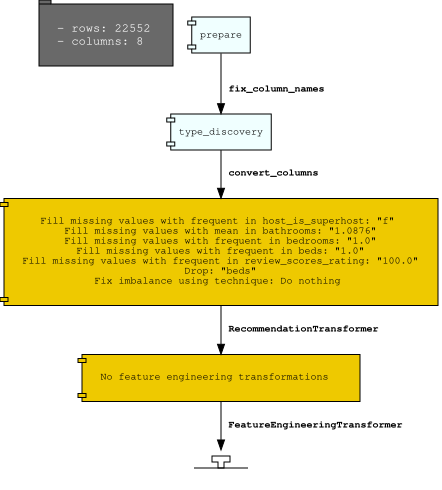

In [109]:
berlin_ds_transormed.visualize_transforms()

In [58]:
X.head()

,host_is_superhost,accommodates,bathrooms,bedrooms,price,minimum_nights,number_of_reviews,review_scores_rating
0,1,3,1.0,1.0,60.0,4,118,93.0
1,0,2,1.0,1.0,17.0,2,6,100.0
2,0,4,1.0,1.0,90.0,62,143,92.0
3,0,2,1.0,1.0,26.0,5,25,88.0
4,1,2,1.0,1.0,42.0,2,197,96.0


## III. Data Exploration for Berlin

In [111]:
# Let's try to work on source files 

berlinsrcfile = "listings_berlin_11_2019.csv"

data_berlin = pd.read_csv(f"oci://{bucket}@{namespace}/{berlinsrcfile}",
                         storage_options=default_signer())
print(f"Source file for Berlin: {berlinsrcfile}")
print(f"size {data_berlin.shape}")


Source file for Berlin: listings_berlin_11_2019.csv
size (22552, 96)


In [112]:
data_berlin.head()

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,requires_license,license,jurisdiction_names,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,2015,https://www.airbnb.com/rooms/2015,20181107122246,2018-11-07,Berlin-Mitte Value! Quiet courtyard/very central,"Great location! 30 of 75 sq meters. This wood floored/high ceiling typical Berlin ""Altbau"" section of an apartment consists of 1 simple large room, a small kitchen and a bathroom + shower. The apartment is in Mitte, close to Prenzlauer Berg/Mauerpark. Perfect for short visits, singles or couples. Your section is closed from the rest of the bigger flat wich is not noticeable. You will not be sharing your space.","A+++ location! This „Einliegerwohnung“ is an extention of a larger apartment with a separate entrance, bathroom and kitchen. The door to the rest of the apartment is soundproof, hidden, locked and barely noticable (behind mirror in pictures). Your 30 sq meters are facing a quiet courtyard. This wood floored/high ceiling typical Berlin ""Altbau"" apartment consists of 1 large room with a large double bed, optionally with an extra matress for a 3rd guest), a small kitchen suitable for preparing simple meals, a bathroom + shower + bathtub and of course your own entrance (all linens and towels are provided.) it is located facing a quiet courtyard, it is clean cozy and an authentic ""Berlin"" place to live. The place is in Mitte, close to Prenzlauer Berg one block from Kastanienallee, Zionskirchplatz, Rosenthaler Platz and Mauerpark. Generally this area is lively with galleries, museums, resturants, cafes, flea markets, bars, clubs, shops, good take away food, a park, U-Bahn, trams, supermarket","Great location! 30 of 75 sq meters. This wood floored/high ceiling typical Berlin ""Altbau"" section of an apartment consists of 1 simple large room, a small kitchen and a bathroom + shower. The apartment is in Mitte, close to Prenzlauer Berg/Mauerpark. Perfect for short visits, singles or couples. Your section is closed from the rest of the bigger flat wich is not noticeable. You will not be sharing your space. A+++ location! This „Einliegerwohnung“ is an extention of a larger apartment with a separate entrance, bathroom and kitchen. The door to the rest of the apartment is soundproof, hidden, locked and barely noticable (behind mirror in pictures). Your 30 sq meters are facing a quiet courtyard. This wood floored/high ceiling typical Berlin ""Altbau"" apartment consists of 1 large room with a large double bed, optionally with an extra matress for a 3rd guest), a small kitchen suitable for preparing simple meals, a bathroom + shower + bathtub and of course your own entrance (all linens a",none,"It is located in the former East Berlin area of Kastanienallee and Zionskirchplatz (Berlins only natural elevation), very charming and original turn of the last century architecture; this area was barely been destroyed during the war. Close to galleries, resturants, museums, flea markets, cafes, bars, clubs, shops, good take away food, a park, great public transportation: U-Bahn, S-Bahn, Trams, Busses, supermarkets etc.",...,t,NaN,NaN,f,f,strict_14_with_grace_period,f,f,4,3.76
1,2695,https://www.airbnb.com/rooms/2695,20181107122246,2018-11-07,Prenzlauer Berg close to Mauerpark,NaN,"In the summertime we are spending most of our weekends in our little house in our garden and want to use the opportunity to rent a room in our cosy 2 bedroom apartment. But we might also stay in the other room. We will be very happy to give you tips on things to do and see in Berlin and make sure your stay runs smoothly. The room is about 25 square meters and is located on the 2nd floor. The bed measures 180 cm x 200 cm and is fitted with a kapok futon, which is a hard-ish mattress but which we find very pleasant to sl

In [113]:
# Preprocessing - cast price as float
data_berlin.price = data_berlin.price.apply(lambda x: x.replace("$", ""))
data_berlin.price = data_berlin.price.apply(lambda x: x.replace(",", ""))
data_berlin.price = data_berlin.price.astype("float")
data_berlin.price.describe()

count    22552.000000
mean        67.143668
std        220.266210
min          0.000000
25%         30.000000
50%         45.000000
75%         70.000000
max       9000.000000
Name: price, dtype: float64

In [114]:
# Enrich data by calculate zip code relation to price
# amenities_len -> value for comparing number of amenities across offerts
# zip_count -> number of offerts in close location
# zip_price -> average price for offerts in the same location

temp_zipcode = data_berlin.zipcode.copy()
data_berlin['zipcode2'] = temp_zipcode.str.replace("\D+", "", ).copy()
data_berlin.zipcode2.fillna(0, inplace=True)
x_count = data_berlin.groupby('zipcode2')['id'].nunique()
x_mean = data_berlin.groupby('zipcode2')['price'].mean()

x_count_dict = x_count.to_dict()
x_mean_dict = x_mean.to_dict()

a1 = np.zeros((len(data_berlin), 6))
print(a1)
for i in range(0,len(data_berlin)):
    val = data_berlin.zipcode2[i]
    a1[i][0] = data_berlin.id[i]
    a1[i][1] = x_count_dict[val]
    a1[i][2] = x_mean_dict[val]
    a1[i][3] = val
    a1[i][4] = len(data_berlin.amenities[i])

data_berlin['amenities_len'] = a1[:,3]
data_berlin['zipcode_count'] = a1[:,1]
data_berlin['zipcode_price'] = a1[:,2]
print(data_berlin.head())

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]
     id                        listing_url       scrape_id last_scraped  \
0  2015  https://www.airbnb.com/rooms/2015  20181107122246   2018-11-07   
1  2695  https://www.airbnb.com/rooms/2695  20181107122246   2018-11-07   
2  3176  https://www.airbnb.com/rooms/3176  20181107122246   2018-11-07   
3  3309  https://www.airbnb.com/rooms/3309  20181107122246   2018-11-07   
4  7071  https://www.airbnb.com/rooms/7071  20181107122246   2018-11-07   

                                               name  \
0  Berlin-Mitte Value! Quiet courtyard/very central   
1                Prenzlauer Berg close to Mauerpark   
2                   Fabulous Flat in great Location   
3                 BerlinSpot Schöneberg near KaDeWe   
4                  BrightRoom with sunny greenview!   

                                                                                      

In [115]:
# Preprocessing - get rid of outliers
print("99.7% properties have a price lower than {0: .2f}".format(np.percentile(data_berlin.price, 99.7)))
data_berlin = data_berlin[(data_berlin.price <= np.percentile(data_berlin.price, 99.7)) & (data_berlin.price > 0)]

99.7% properties have a price lower than  550.00


In [116]:
cols = ['price', 'host_is_superhost', 'bedrooms', 'number_of_reviews', 'review_scores_rating', 'beds', 'bathrooms']
cols2 = ['accommodates', 'amenities_len', 'minimum_nights', 'zipcode_count', 'zipcode_price']
cols = cols + cols2
cols

['price',
 'host_is_superhost',
 'bedrooms',
 'number_of_reviews',
 'review_scores_rating',
 'beds',
 'bathrooms',
 'accommodates',
 'amenities_len',
 'minimum_nights',
 'zipcode_count',
 'zipcode_price']

In [117]:
# Preprocessing - replace NaN values with mean from column
# With checking before and after replacement

print(data_berlin[cols].isna().sum())
data_berlin.fillna((data_berlin[cols].mean()), inplace=True)
print(data_berlin[cols].isna().sum())

price                      0
host_is_superhost         25
bedrooms                  18
number_of_reviews          0
review_scores_rating    4349
beds                      39
bathrooms                 32
accommodates               0
amenities_len              0
minimum_nights             0
zipcode_count              0
zipcode_price              0
dtype: int64
price                    0
host_is_superhost       25
bedrooms                 0
number_of_reviews        0
review_scores_rating     0
beds                     0
bathrooms                0
accommodates             0
amenities_len            0
minimum_nights           0
zipcode_count            0
zipcode_price            0
dtype: int64


In [118]:
# Convert remaining columns to float type
data_berlin['number_of_reviews'] = data_berlin['number_of_reviews'].astype(float)
data_berlin['accommodates'] = data_berlin['accommodates'].astype(float)
data_berlin['amenities_len'] = data_berlin['amenities_len'].astype(float)
data_berlin['minimum_nights'] = data_berlin['minimum_nights'].astype(float)

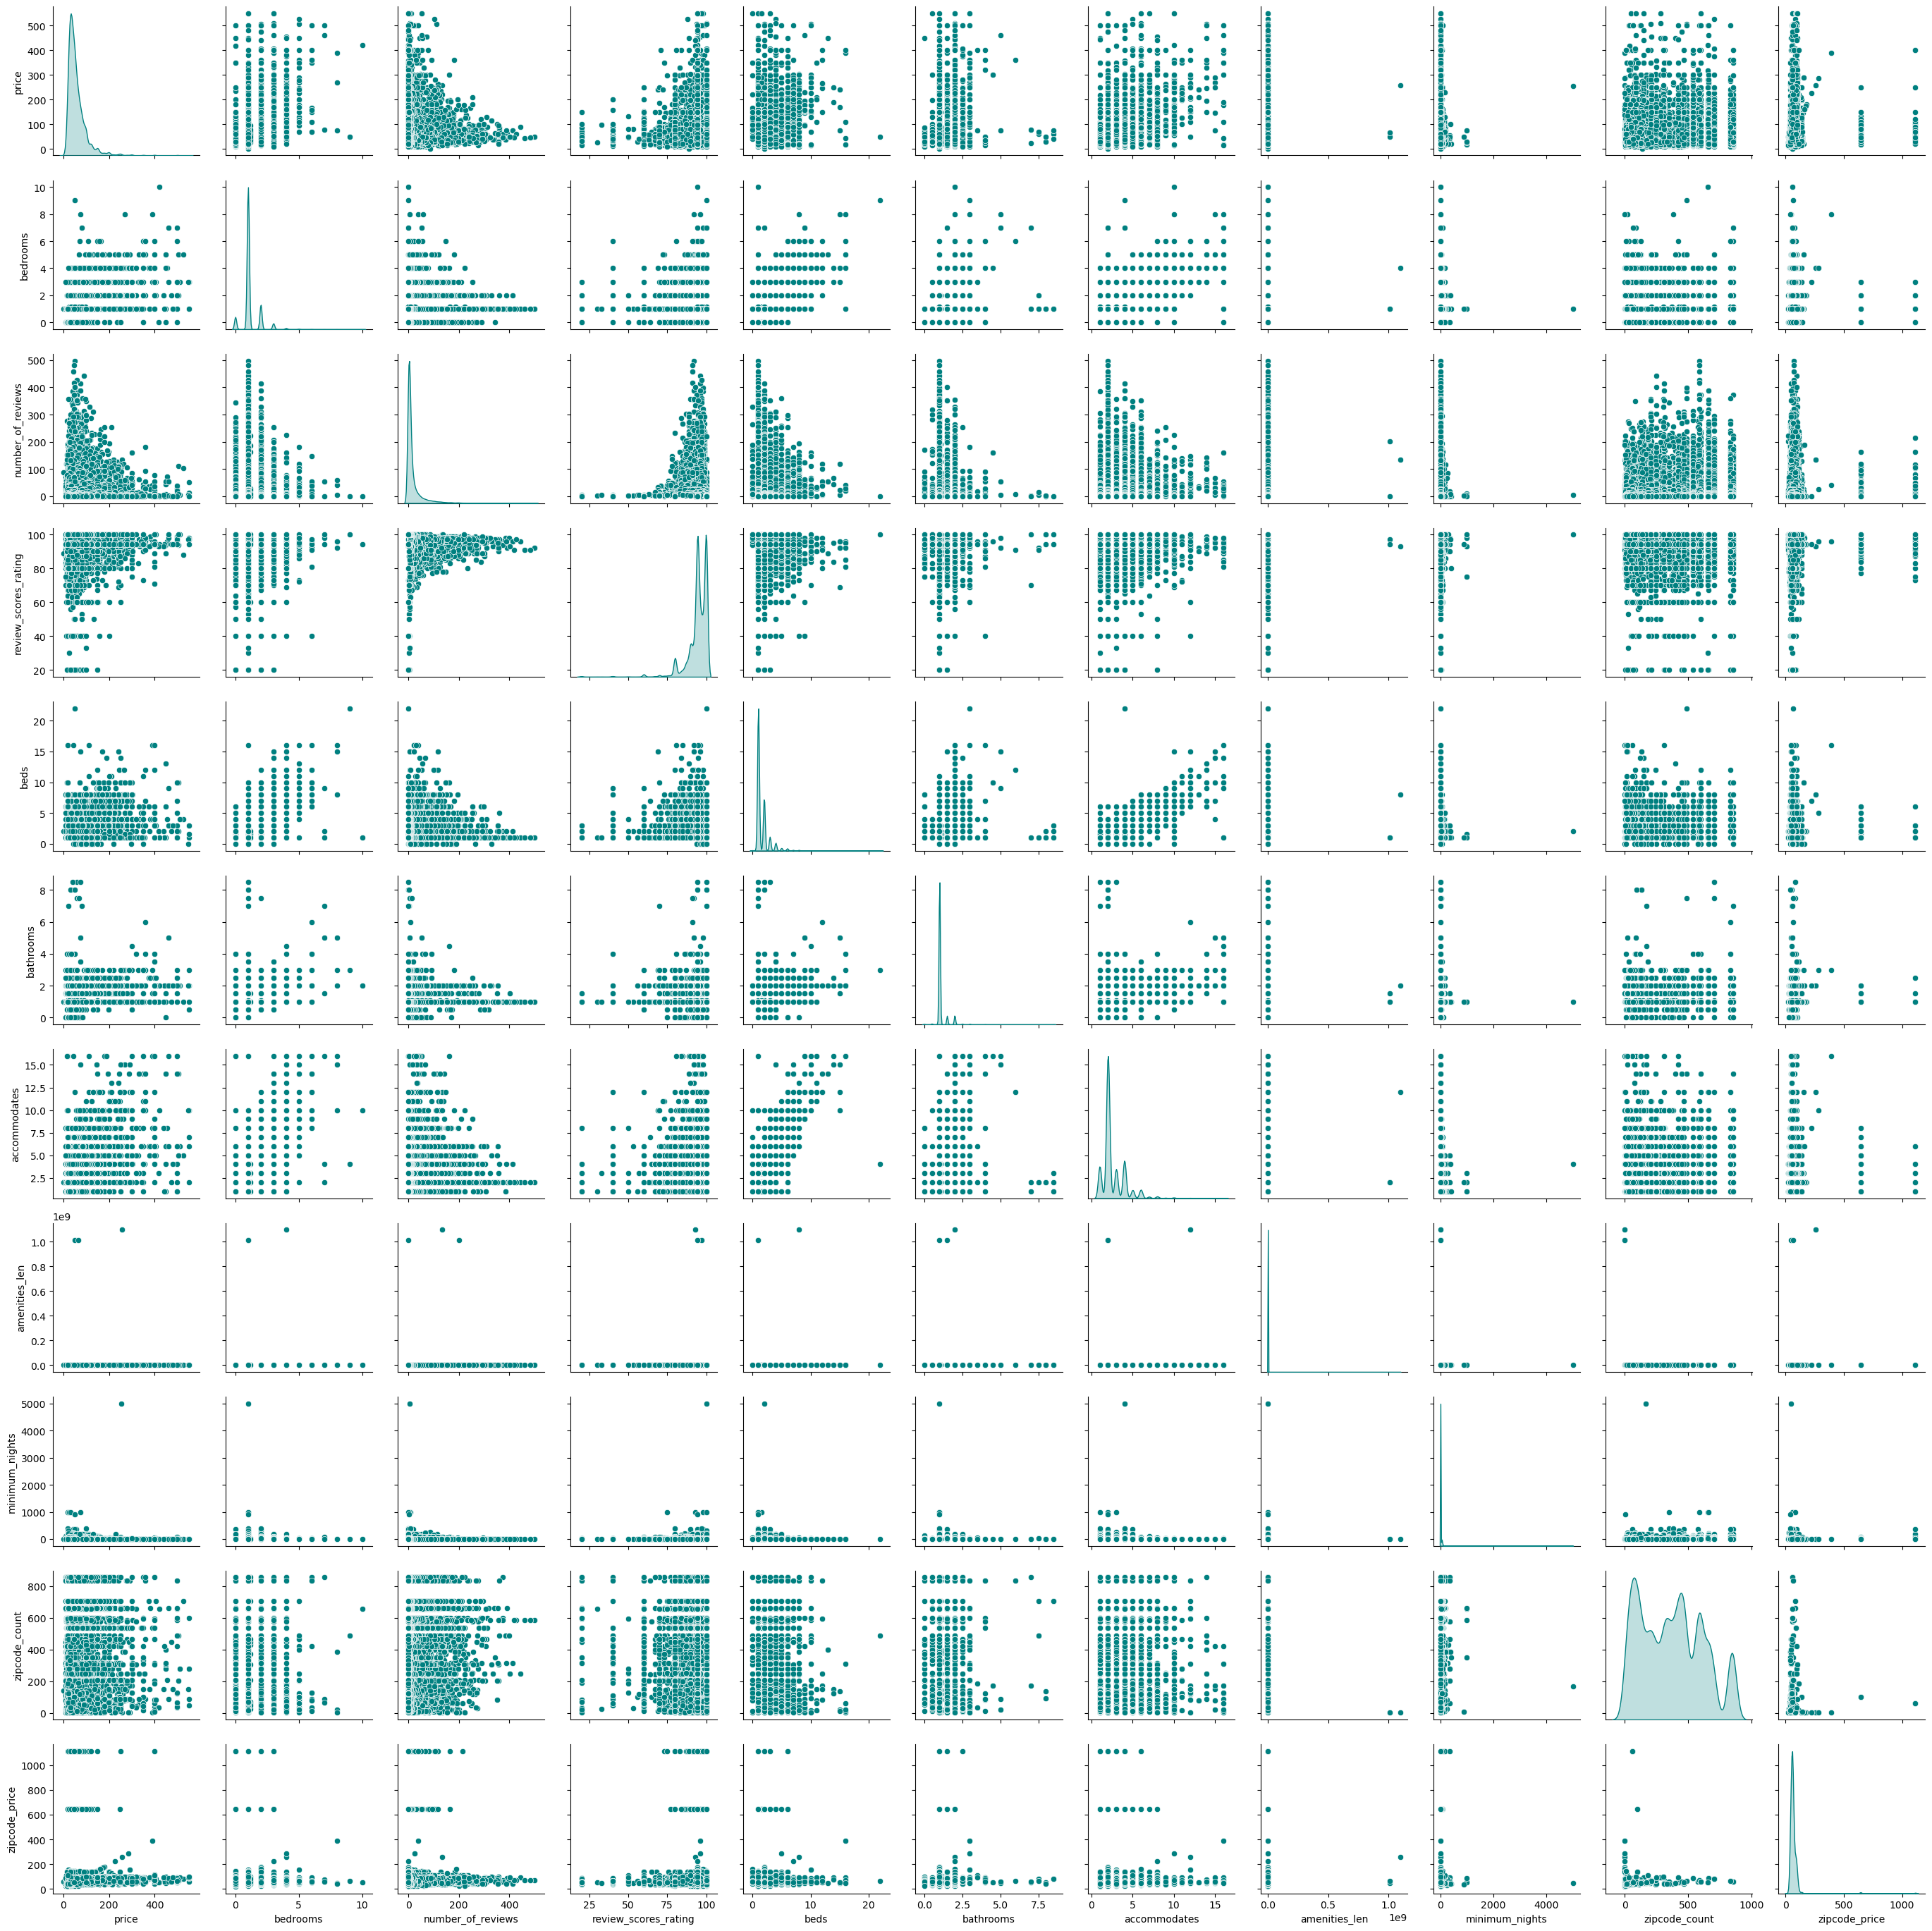

<Figure size 640x480 with 0 Axes>

In [119]:
set_of_data =[data_berlin]
set_of_city = ['berlin']

sns.pairplot(data_berlin[cols], height=2.5, diag_kind='kde')
plt.tight_layout()
plt.savefig('berlin_matrix_pair_plot.png', dpi=300)

plt.show()
plt.clf() # Clean parirplot figure from sns

In [120]:
print(data_berlin[cols].info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 22479 entries, 0 to 22551
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price                 22479 non-null  float64
 1   host_is_superhost     22454 non-null  object 
 2   bedrooms              22479 non-null  float64
 3   number_of_reviews     22479 non-null  float64
 4   review_scores_rating  22479 non-null  float64
 5   beds                  22479 non-null  float64
 6   bathrooms             22479 non-null  float64
 7   accommodates          22479 non-null  float64
 8   amenities_len         22479 non-null  float64
 9   minimum_nights        22479 non-null  float64
 10  zipcode_count         22479 non-null  float64
 11  zipcode_price         22479 non-null  float64
dtypes: float64(11), object(1)
memory usage: 2.2+ MB
None


In [121]:
# Preparing data to show in heatmap
print(data_berlin[cols].describe())
print(data_berlin[cols].info())
data_berlin[cols].values.T
print(cols)
print(data_berlin[cols].info())
cols_for_heatmap = cols.copy()
cols_for_heatmap.remove('host_is_superhost')

              price      bedrooms  number_of_reviews  review_scores_rating  \
count  22479.000000  22479.000000       22479.000000          22479.000000   
mean      58.308021      1.158809          17.877619             94.414010   
std       45.678653      0.637756          36.814993              6.853521   
min        1.000000      0.000000           0.000000             20.000000   
25%       30.000000      1.000000           1.000000             93.000000   
50%       45.000000      1.000000           5.000000             95.000000   
75%       70.000000      1.000000          16.000000            100.000000   
max      550.000000     10.000000         498.000000            100.000000   

               beds     bathrooms  accommodates  amenities_len  \
count  22479.000000  22479.000000  22479.000000   2.247900e+04   
mean       1.617291      1.091371      2.631612   1.497655e+05   
std        1.161282      0.324717      1.489118   1.202406e+07   
min        0.000000      0.000000

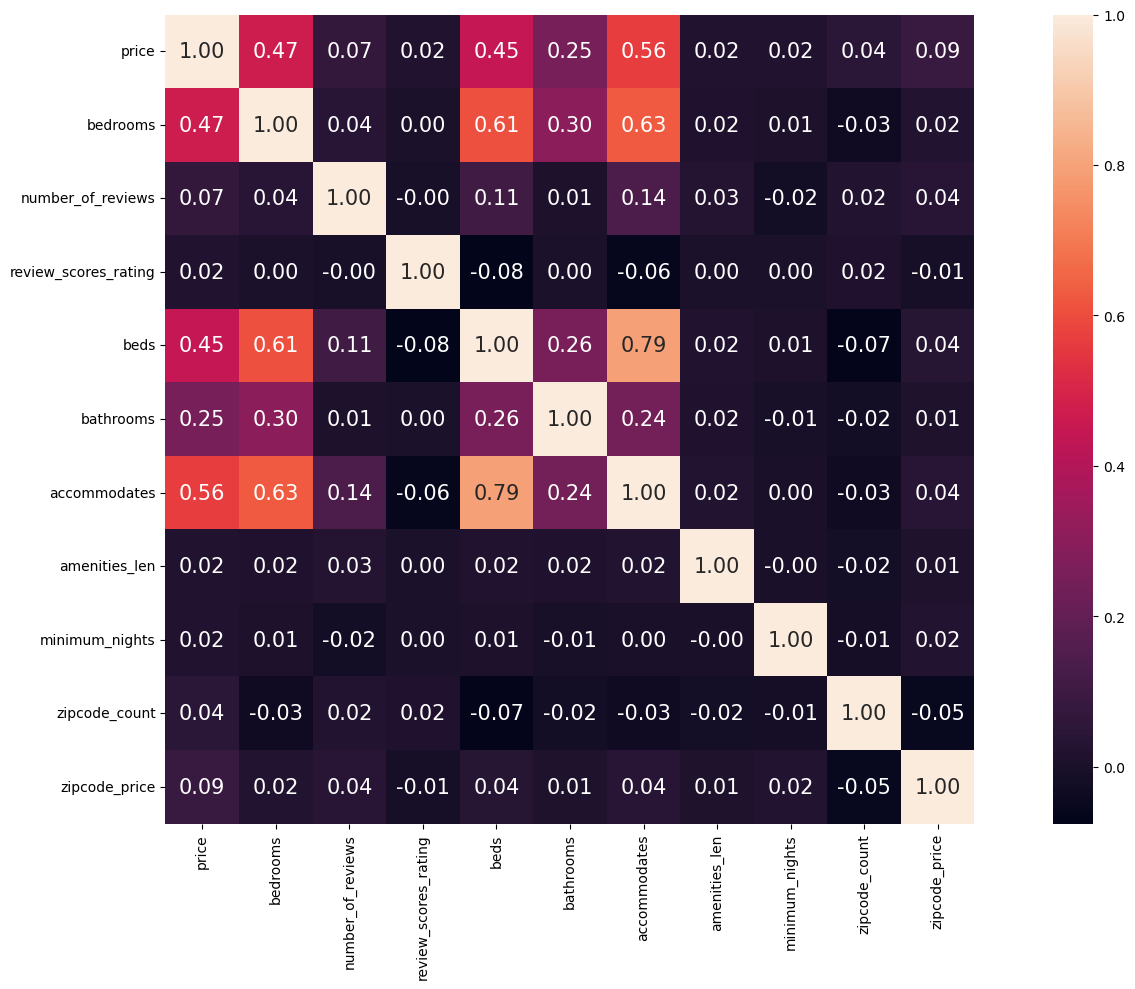

In [122]:
cm = np.corrcoef(data_berlin[cols_for_heatmap].values.T)
plt.figure(figsize = (16,10))
hm = sns.heatmap(cm,
                 cbar=True,
                 annot=True,
                 square=True,
                 fmt='.2f',
                 annot_kws={'size': 15},
                 yticklabels=cols_for_heatmap,
                 xticklabels=cols_for_heatmap)

plt.tight_layout()
plt.savefig('berlin_heatmap.png', dpi=300)
plt.show()

## IV. Berlin - modeling 

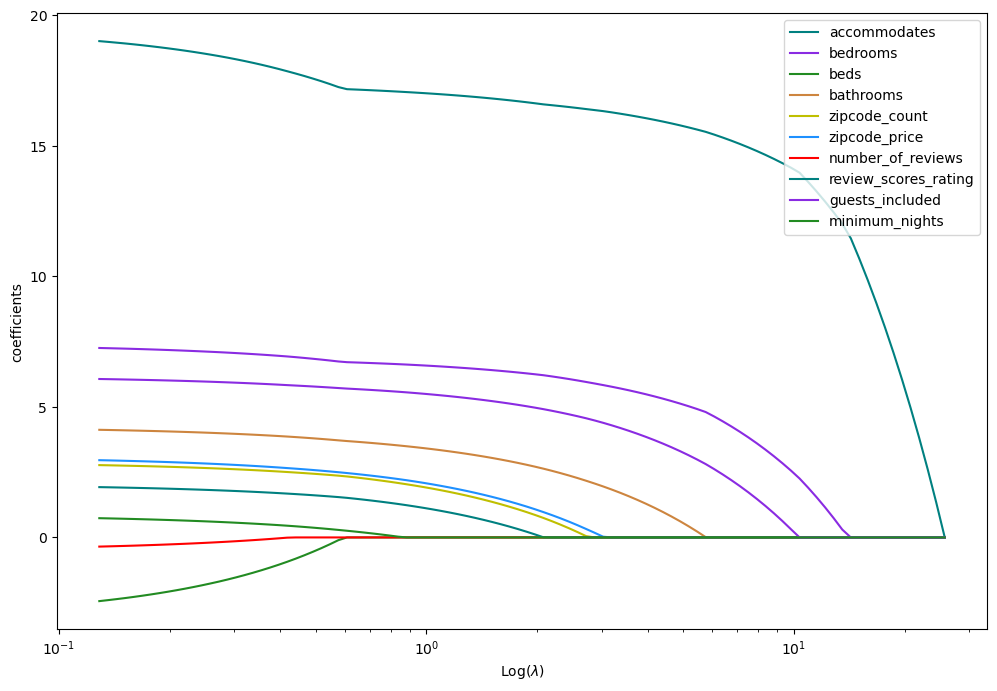

In [123]:
variables = ['accommodates','bedrooms','beds','bathrooms','zipcode_count','zipcode_price','number_of_reviews','review_scores_rating', 'guests_included', 'minimum_nights']


data_subset = data_berlin.loc[:, variables + ['price']]
data_subset.dropna(inplace=True)

X = data_subset.loc[:,variables]
X = preprocessing.scale(X)
y = np.array(data_subset.price)

alphas_lasso, coefs_lasso, _ = linear_model.lasso_path(X, y, eps=5e-3)

# Display results
plt.figure(figsize = (12,8))

for i in range(X.shape[1]):
    plt.plot(alphas_lasso, coefs_lasso[i], label = variables[i])

plt.xscale('log')
plt.xlabel('Log($\\lambda$)')
plt.ylabel('coefficients')
#plt.title('Lasso paths - Sklearn')
plt.legend()
plt.axis('tight')

plt.savefig('berlin_lasso.png', dpi=300)

## V. Munich - EDA

In [126]:
# Let's try to work on source files 

munichsrcfile = "listings_munich_11_2019.csv"

data_munich = pd.read_csv(f"oci://{bucket}@{namespace}/{munichsrcfile}",
                         storage_options=default_signer())
print(f"Source file for Munich: {munichsrcfile}")
print(f"size {data_munich.shape}")


Source file for Munich: listings_munich_11_2019.csv
size (11481, 106)


In [127]:
data_munich.head()

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,36720,https://www.airbnb.com/rooms/36720,20191125094942,2019-11-25,"Beautiful 2 rooms flat, Glockenbach","Very quiet, yet centrally located 2 rooms apt. in the hip and popular area of Glockenbach. Convenient public transport, walking distance to Viktualienmarkt, Marienplatz or Isar river, Gärtnerplatz shopping area and some of the best and coolest restaurants in town.","2-Zimmer Altbauwohung Beste Lage, zentral, im angesagten Glockenbachviertel Beschreibung: 2-Zimmer Altbauwohnung in schönem Stadthaus. 57m2 Ausstattung: Parkettböden, EBK, Bad mit Fenster. komplett möbiliert, Waschmaschine, Spülmaschine Lage: sehr ruhige dennoch super zentrale Lage. Nahe Isar. U-Bahn Sendlinger Tor/Frauenhoferstr, Tram Sendlinger Tor/Müllerstr.","Very quiet, yet centrally located 2 rooms apt. in the hip and popular area of Glockenbach. Convenient public transport, walking distance to Viktualienmarkt, Marienplatz or Isar river, Gärtnerplatz shopping area and some of the best and coolest restaurants in town. 2-Zimmer Altbauwohung Beste Lage, zentral, im angesagten Glockenbachviertel Beschreibung: 2-Zimmer Altbauwohnung in schönem Stadthaus. 57m2 Ausstattung: Parkettböden, EBK, Bad mit Fenster. komplett möbiliert, Waschmaschine, Spülmaschine Lage: sehr ruhige dennoch super zentrale Lage. Nahe Isar. U-Bahn Sendlinger Tor/Frauenhoferstr, Tram Sendlinger Tor/Müllerstr. Glockenbachviertel area has the hippest restaurants, cafes und great shopping with amazing unique boutiques and stores, close to the Viktualienmarkt/Marienplatz/Gärtnerplatz, also close to the river Isar, wonderful walking/jogging routes Convenient public transport, walking distance to Viktualienmarkt, Marienplatz, Gärtnerplatz, U-Bahn Sendlinger Tor/Frauenhoferstr,(U",none,"Glockenbachviertel area has the hippest restaurants, cafes und great shopping with amazing unique boutiques and stores, close to the Viktualienmarkt/Marienplatz/Gärtnerplatz, also close to the river Isar, wonderful walking/jogging routes",...,f,f,strict_14_with_grace_period,f,f,1,1,0,0,0.37
1,97945,https://www.airbnb.com/rooms/97945,20191125094942,2019-11-25,Deluxw-Apartm. with roof terrace,NaN,"We offer a modern, quiet apartment with a sunny roof terrace for 1-2 persons in the vicinity of the Hospital Grosshadern. The apartment is on the top floor of a two-family house. The living room is very bright due to the large window to the terrace, both the living room and on the terrace there is enough comfortable seating and a small table. From the living you reach the open kitchen which is equipped with everything you need in order to be self-supplied (including a refrigerator and a small oven). There are many books and even a TV in our apartment. In the bedroom with double bed are also some cupboards and thus enough storage space so that our guests can store their belongings. For the environment: There are about 5 minutes to the subway line 6, which goes directly to the Oktoberfestwiese into the city center and to a bohemian part of munich, which is called Schwabing.The nearest shoppingcenter is across the Subwaystation also 5 minutes away. Parking is available in the street nea","We offer a modern, quiet apartment with a sunny roof terrace for 1-2 persons in the vicinity of the Hospital Grosshadern. The apartment is on the top floor of a two-family house. The living room is very bright due to the large window to the terrace, both the living room and on the terrace there is enough comfortable seating and a small table. From the living you reach the open kitchen which is equipped with everything you nee

In [128]:
# Preprocessing - cast price as float
data_munich.price = data_munich.price.apply(lambda x: x.replace("$", ""))
data_munich.price = data_munich.price.apply(lambda x: x.replace(",", ""))
data_munich.price = data_munich.price.astype("float")
data_munich.price.describe()

count    11481.000000
mean       116.336469
std        168.078321
min          8.000000
25%         55.000000
50%         82.000000
75%        130.000000
max       9000.000000
Name: price, dtype: float64

In [129]:
# Enrich data by calculate zip code relation to price
# amenities_len -> value for comparing number of amenities across offerts
# zip_count -> number of offerts in close location
# zip_price -> average price for offerts in the same location

temp_zipcode = data_munich.zipcode.copy()
data_munich['zipcode2'] = temp_zipcode.str.replace("\D+", "", ).copy()

data_munich.zipcode2.fillna(0, inplace=True)

x_count = data_munich.groupby('zipcode2')['id'].nunique()
x_mean = data_munich.groupby('zipcode2')['price'].mean()

x_count_dict = x_count.to_dict()
x_mean_dict = x_mean.to_dict()

a1 = np.zeros((len(data_munich), 6))
print(a1)
for i in range(0,len(data_munich)):
    val = data_munich.zipcode2[i]
    a1[i][0] = data_munich.id[i]
    a1[i][1] = x_count_dict[val]
    a1[i][2] = x_mean_dict[val]
    a1[i][3] = val
    a1[i][4] = len(data_munich.amenities[i])

data_munich['amenities_len'] = a1[:,3]
data_munich['zipcode_count'] = a1[:,1]
data_munich['zipcode_price'] = a1[:,2]
print(data_munich.head())

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]
       id                          listing_url       scrape_id last_scraped  \
0   36720   https://www.airbnb.com/rooms/36720  20191125094942   2019-11-25   
1   97945   https://www.airbnb.com/rooms/97945  20191125094942   2019-11-25   
2  114695  https://www.airbnb.com/rooms/114695  20191125094942   2019-11-25   
3  127383  https://www.airbnb.com/rooms/127383  20191125094942   2019-11-25   
4  157808  https://www.airbnb.com/rooms/157808  20191125094942   2019-11-25   

                                  name  \
0  Beautiful 2 rooms flat, Glockenbach   
1     Deluxw-Apartm. with roof terrace   
2   Apartment Munich/East with sundeck   
3    City apartment next to Pinakothek   
4          Near Olympia,English Garden   

                                                                                                                                            

In [130]:
# Preprocessing - get rid of outliers
print("99.7% properties have a price lower than {0: .2f}".format(np.percentile(data_munich.price, 99.7)))
data_munich = data_munich[(data_munich.price <= np.percentile(data_munich.price, 99.7)) & (data_munich.price > 0)]

99.7% properties have a price lower than  999.00


In [131]:
cols = ['price', 'host_is_superhost', 'bedrooms', 'number_of_reviews', 'review_scores_rating', 'beds', 'bathrooms']
cols2 = ['accommodates', 'amenities_len', 'minimum_nights', 'zipcode_count', 'zipcode_price']
cols = cols + cols2
cols

['price',
 'host_is_superhost',
 'bedrooms',
 'number_of_reviews',
 'review_scores_rating',
 'beds',
 'bathrooms',
 'accommodates',
 'amenities_len',
 'minimum_nights',
 'zipcode_count',
 'zipcode_price']

In [132]:
data_munich['number_of_reviews'] = data_munich['number_of_reviews'].astype(float)
data_munich['accommodates'] = data_munich['accommodates'].astype(float)
data_munich['amenities_len'] = data_munich['amenities_len'].astype(float)
data_munich['minimum_nights'] = data_munich['minimum_nights'].astype(float)

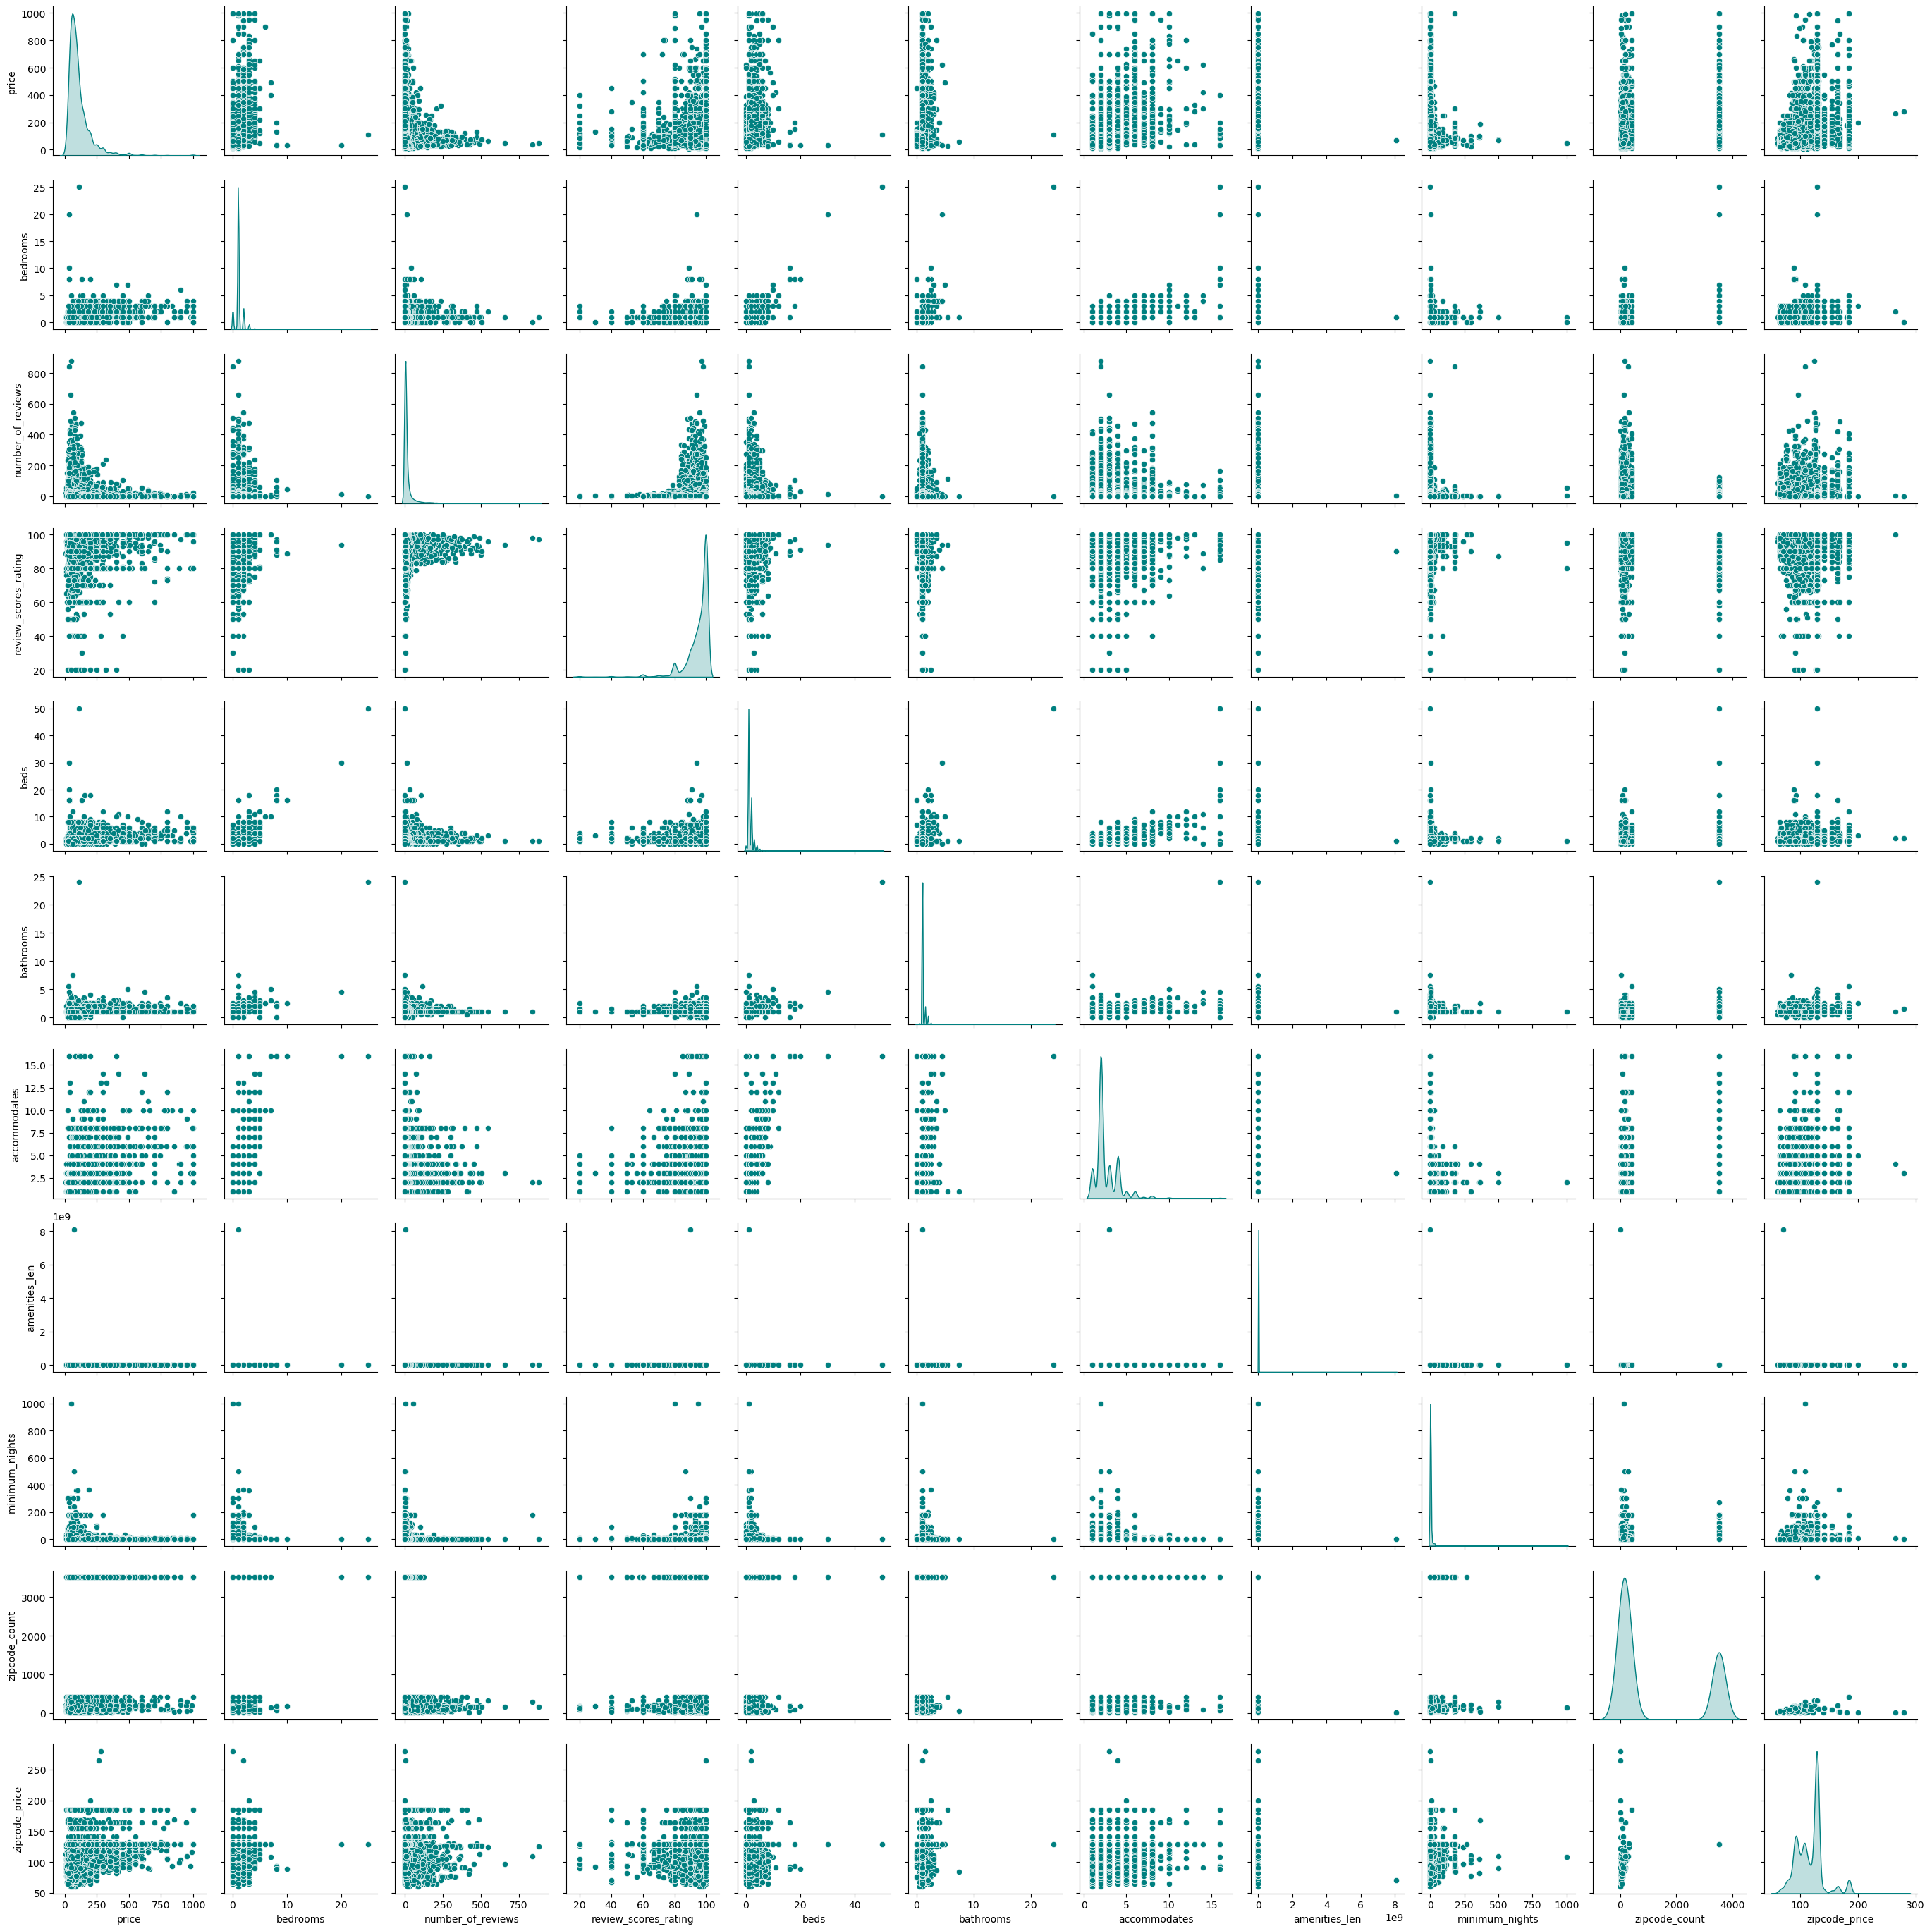

<Figure size 640x480 with 0 Axes>

In [135]:
sns.pairplot(data_munich[cols], height=2.5, diag_kind='kde')
plt.tight_layout()
plt.savefig('munich_matrix_pair_plot.png', dpi=300)

plt.show()
plt.clf() # Clean parirplot figure from sns

In [136]:
print(data_munich[cols].info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 11454 entries, 0 to 11480
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price                 11454 non-null  float64
 1   host_is_superhost     11431 non-null  object 
 2   bedrooms              11424 non-null  float64
 3   number_of_reviews     11454 non-null  float64
 4   review_scores_rating  8735 non-null   float64
 5   beds                  11436 non-null  float64
 6   bathrooms             11433 non-null  float64
 7   accommodates          11454 non-null  float64
 8   amenities_len         11454 non-null  float64
 9   minimum_nights        11454 non-null  float64
 10  zipcode_count         11454 non-null  float64
 11  zipcode_price         11454 non-null  float64
dtypes: float64(11), object(1)
memory usage: 1.1+ MB
None


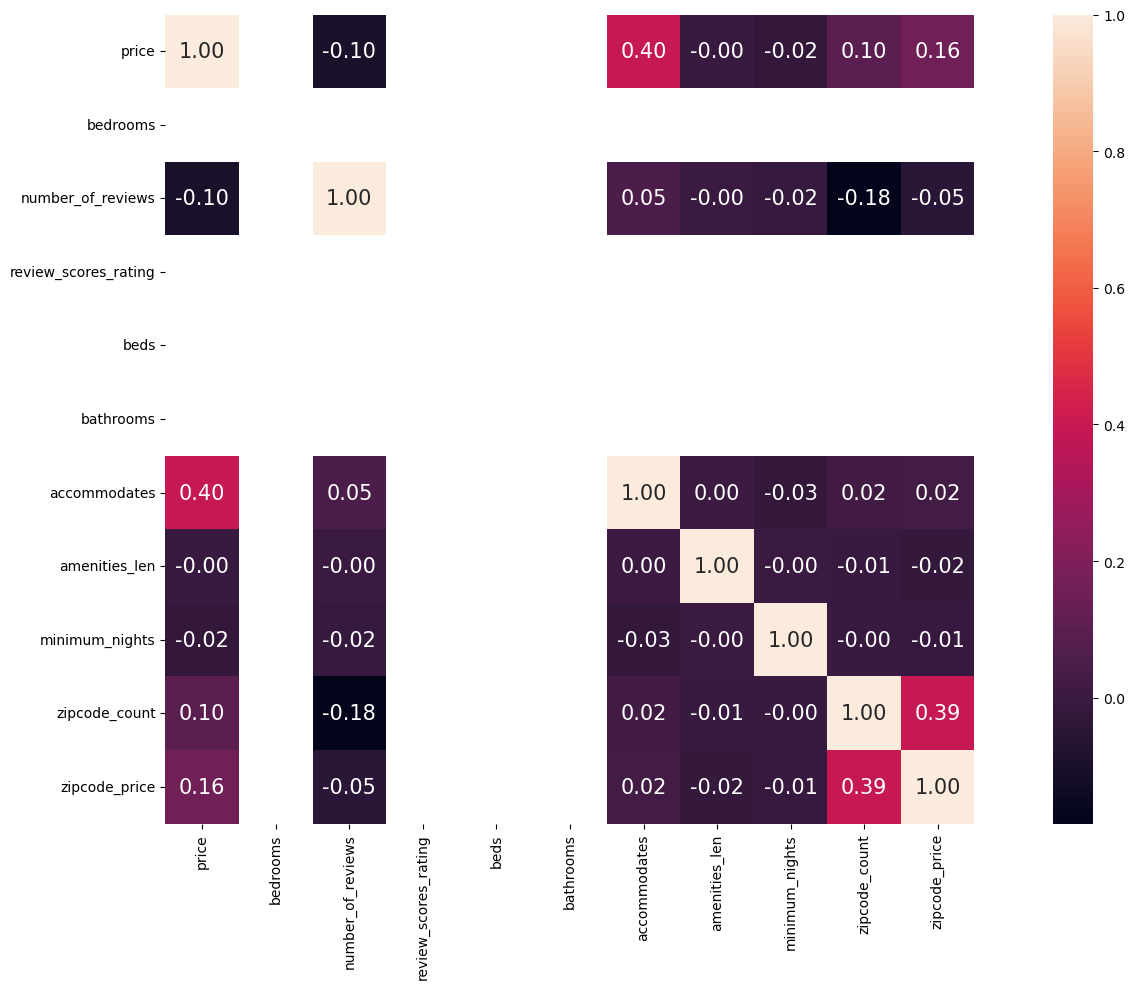

In [137]:
cm = np.corrcoef(data_munich[cols_for_heatmap].values.T)
plt.figure(figsize = (16,10))

hm = sns.heatmap(cm,
                 cbar=True,
                 annot=True,
                 square=True,
                 fmt='.2f',
                 annot_kws={'size': 15},
                 yticklabels=cols_for_heatmap,
                 xticklabels=cols_for_heatmap)

plt.tight_layout()
plt.savefig('munich_heatmap.png', dpi=300)
plt.show()

## VI Munich - data modeling

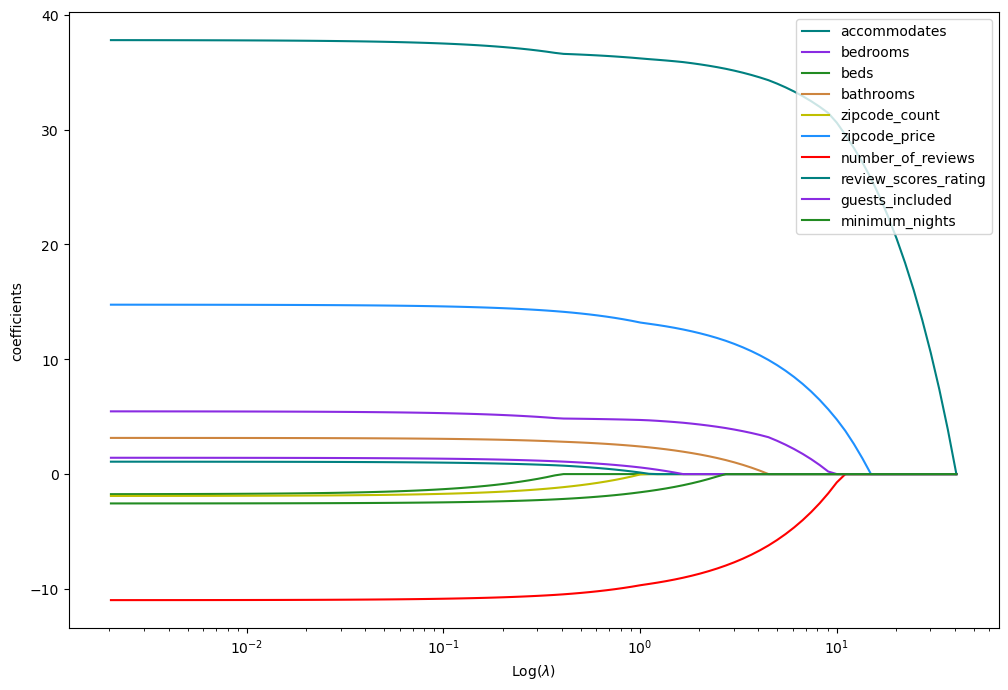

In [139]:
variables = ['accommodates','bedrooms','beds','bathrooms','zipcode_count','zipcode_price','number_of_reviews','review_scores_rating', 'guests_included', 'minimum_nights']


data_subset = data_munich.loc[:, variables + ['price']]
data_subset.dropna(inplace=True)

X = data_subset.loc[:,variables]
X = preprocessing.scale(X)
y = np.array(data_subset.price)

alphas_lasso, coefs_lasso, _ = linear_model.lasso_path(X, y, eps=5e-5)

# Display results
plt.figure(figsize = (12,8))

for i in range(X.shape[1]):
    plt.plot(alphas_lasso, coefs_lasso[i], label = variables[i])

plt.xscale('log')
plt.xlabel('Log($\\lambda$)')
plt.ylabel('coefficients')
#plt.title('Lasso paths - Sklearn')
plt.legend()
plt.axis('tight')

plt.savefig('munich_lasso.png', dpi=300)

## VII Prague - EDA

In [140]:
# Let's try to work on source files 

praguesrcfile = "listings_prague_11_2019.csv"

data_prague = pd.read_csv(f"oci://{bucket}@{namespace}/{praguesrcfile}",
                         storage_options=default_signer())
print(f"Source file for Prague: {praguesrcfile}")
print(f"size {data_prague.shape}")


Source file for Prague: listings_prague_11_2019.csv
size (6782, 74)


In [141]:
# Preprocessing - cast price as float
data_prague.price = data_prague.price.apply(lambda x: x.replace("$", ""))
data_prague.price = data_prague.price.apply(lambda x: x.replace(",", ""))
data_prague.price = data_prague.price.astype("float")
data_prague.price.describe()

count    6.782000e+03
mean     9.016939e+03
std      1.282461e+05
min      0.000000e+00
25%      1.113250e+03
50%      1.705000e+03
75%      2.762750e+03
max      2.866213e+06
Name: price, dtype: float64

In [143]:
# Enrich data by calculate zip code relation to price
# amenities_len -> value for comparing number of amenities across offerts
# zip_count -> number of offerts in close location
# zip_price -> average price for offerts in the same location

temp_zipcode = data_munich.zipcode.copy()
data_prague['zipcode2'] = temp_zipcode.str.replace("\D+", "", ).copy()

data_prague.zipcode2.fillna(0, inplace=True)

x_count = data_prague.groupby('zipcode2')['id'].nunique()
x_mean = data_prague.groupby('zipcode2')['price'].mean()

x_count_dict = x_count.to_dict()
x_mean_dict = x_mean.to_dict()

a1 = np.zeros((len(data_prague), 6))
print(a1)
for i in range(0,len(data_prague)):
    val = data_prague.zipcode2[i]
    a1[i][0] = data_prague.id[i]
    a1[i][1] = x_count_dict[val]
    a1[i][2] = x_mean_dict[val]
    a1[i][3] = val
    a1[i][4] = len(data_prague.amenities[i])

data_prague['amenities_len'] = a1[:,3]
data_prague['zipcode_count'] = a1[:,1]
data_prague['zipcode_price'] = a1[:,2]
print(data_prague.head())

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]
      id                         listing_url       scrape_id last_scraped  \
0   3884   https://www.airbnb.com/rooms/3884  20211218004437   2019-12-18   
1  23163  https://www.airbnb.com/rooms/23163  20211218004437   2019-12-18   
2  23169  https://www.airbnb.com/rooms/23169  20211218004437   2019-12-18   
3  26755  https://www.airbnb.com/rooms/26755  20211218004437   2019-12-18   
4  27916  https://www.airbnb.com/rooms/27916  20211218004437   2019-12-18   

                                                   name  \
0                      Enjoy/relax/hide Old Town Prague   
1  Quiet 1BR directly in the Centre, Air-conditioned 12   
2                   M302-Cozy Serviced Studio in Center   
3                     Central Prague Old Town Top Floor   
4         Cosy & Quiet Studio - Romantic Stay in Zizkov   

                                                  

In [144]:
# Preprocessing - get rid of outliers
print("99.7% properties have a price lower than {0: .2f}".format(np.percentile(data_prague.price, 99.7)))
data_prague = data_prague[(data_prague.price <= np.percentile(data_prague.price, 99.7)) & (data_prague.price > 0)]

99.7% properties have a price lower than  61282.69


In [145]:
cols = ['price', 'host_is_superhost', 'bedrooms', 'number_of_reviews', 'review_scores_rating', 'beds', 'bathrooms']
cols2 = ['accommodates', 'amenities_len', 'minimum_nights', 'zipcode_count', 'zipcode_price']
cols = cols + cols2
cols

['price',
 'host_is_superhost',
 'bedrooms',
 'number_of_reviews',
 'review_scores_rating',
 'beds',
 'bathrooms',
 'accommodates',
 'amenities_len',
 'minimum_nights',
 'zipcode_count',
 'zipcode_price']

In [146]:
# Preprocessing - replace NaN values with mean from column
# With checking before and after replacement

print(data_prague[cols].isna().sum())

data_prague.fillna((data_prague[cols].mean()), inplace=True)

# Why bathromes NaN not cleaned for Prague ?
data_prague['bathrooms'] = data_prague['bathrooms'].replace(np.nan, 0)

print(data_prague[cols].isna().sum())


price                      0
host_is_superhost          0
bedrooms                 795
number_of_reviews          0
review_scores_rating     963
beds                     165
bathrooms               6752
accommodates               0
amenities_len              0
minimum_nights             0
zipcode_count              0
zipcode_price              0
dtype: int64
price                   0
host_is_superhost       0
bedrooms                0
number_of_reviews       0
review_scores_rating    0
beds                    0
bathrooms               0
accommodates            0
amenities_len           0
minimum_nights          0
zipcode_count           0
zipcode_price           0
dtype: int64


In [147]:
data_prague['number_of_reviews'] = data_prague['number_of_reviews'].astype(float)
data_prague['accommodates'] = data_prague['accommodates'].astype(float)
data_prague['amenities_len'] = data_prague['amenities_len'].astype(float)
data_prague['minimum_nights'] = data_prague['minimum_nights'].astype(float)

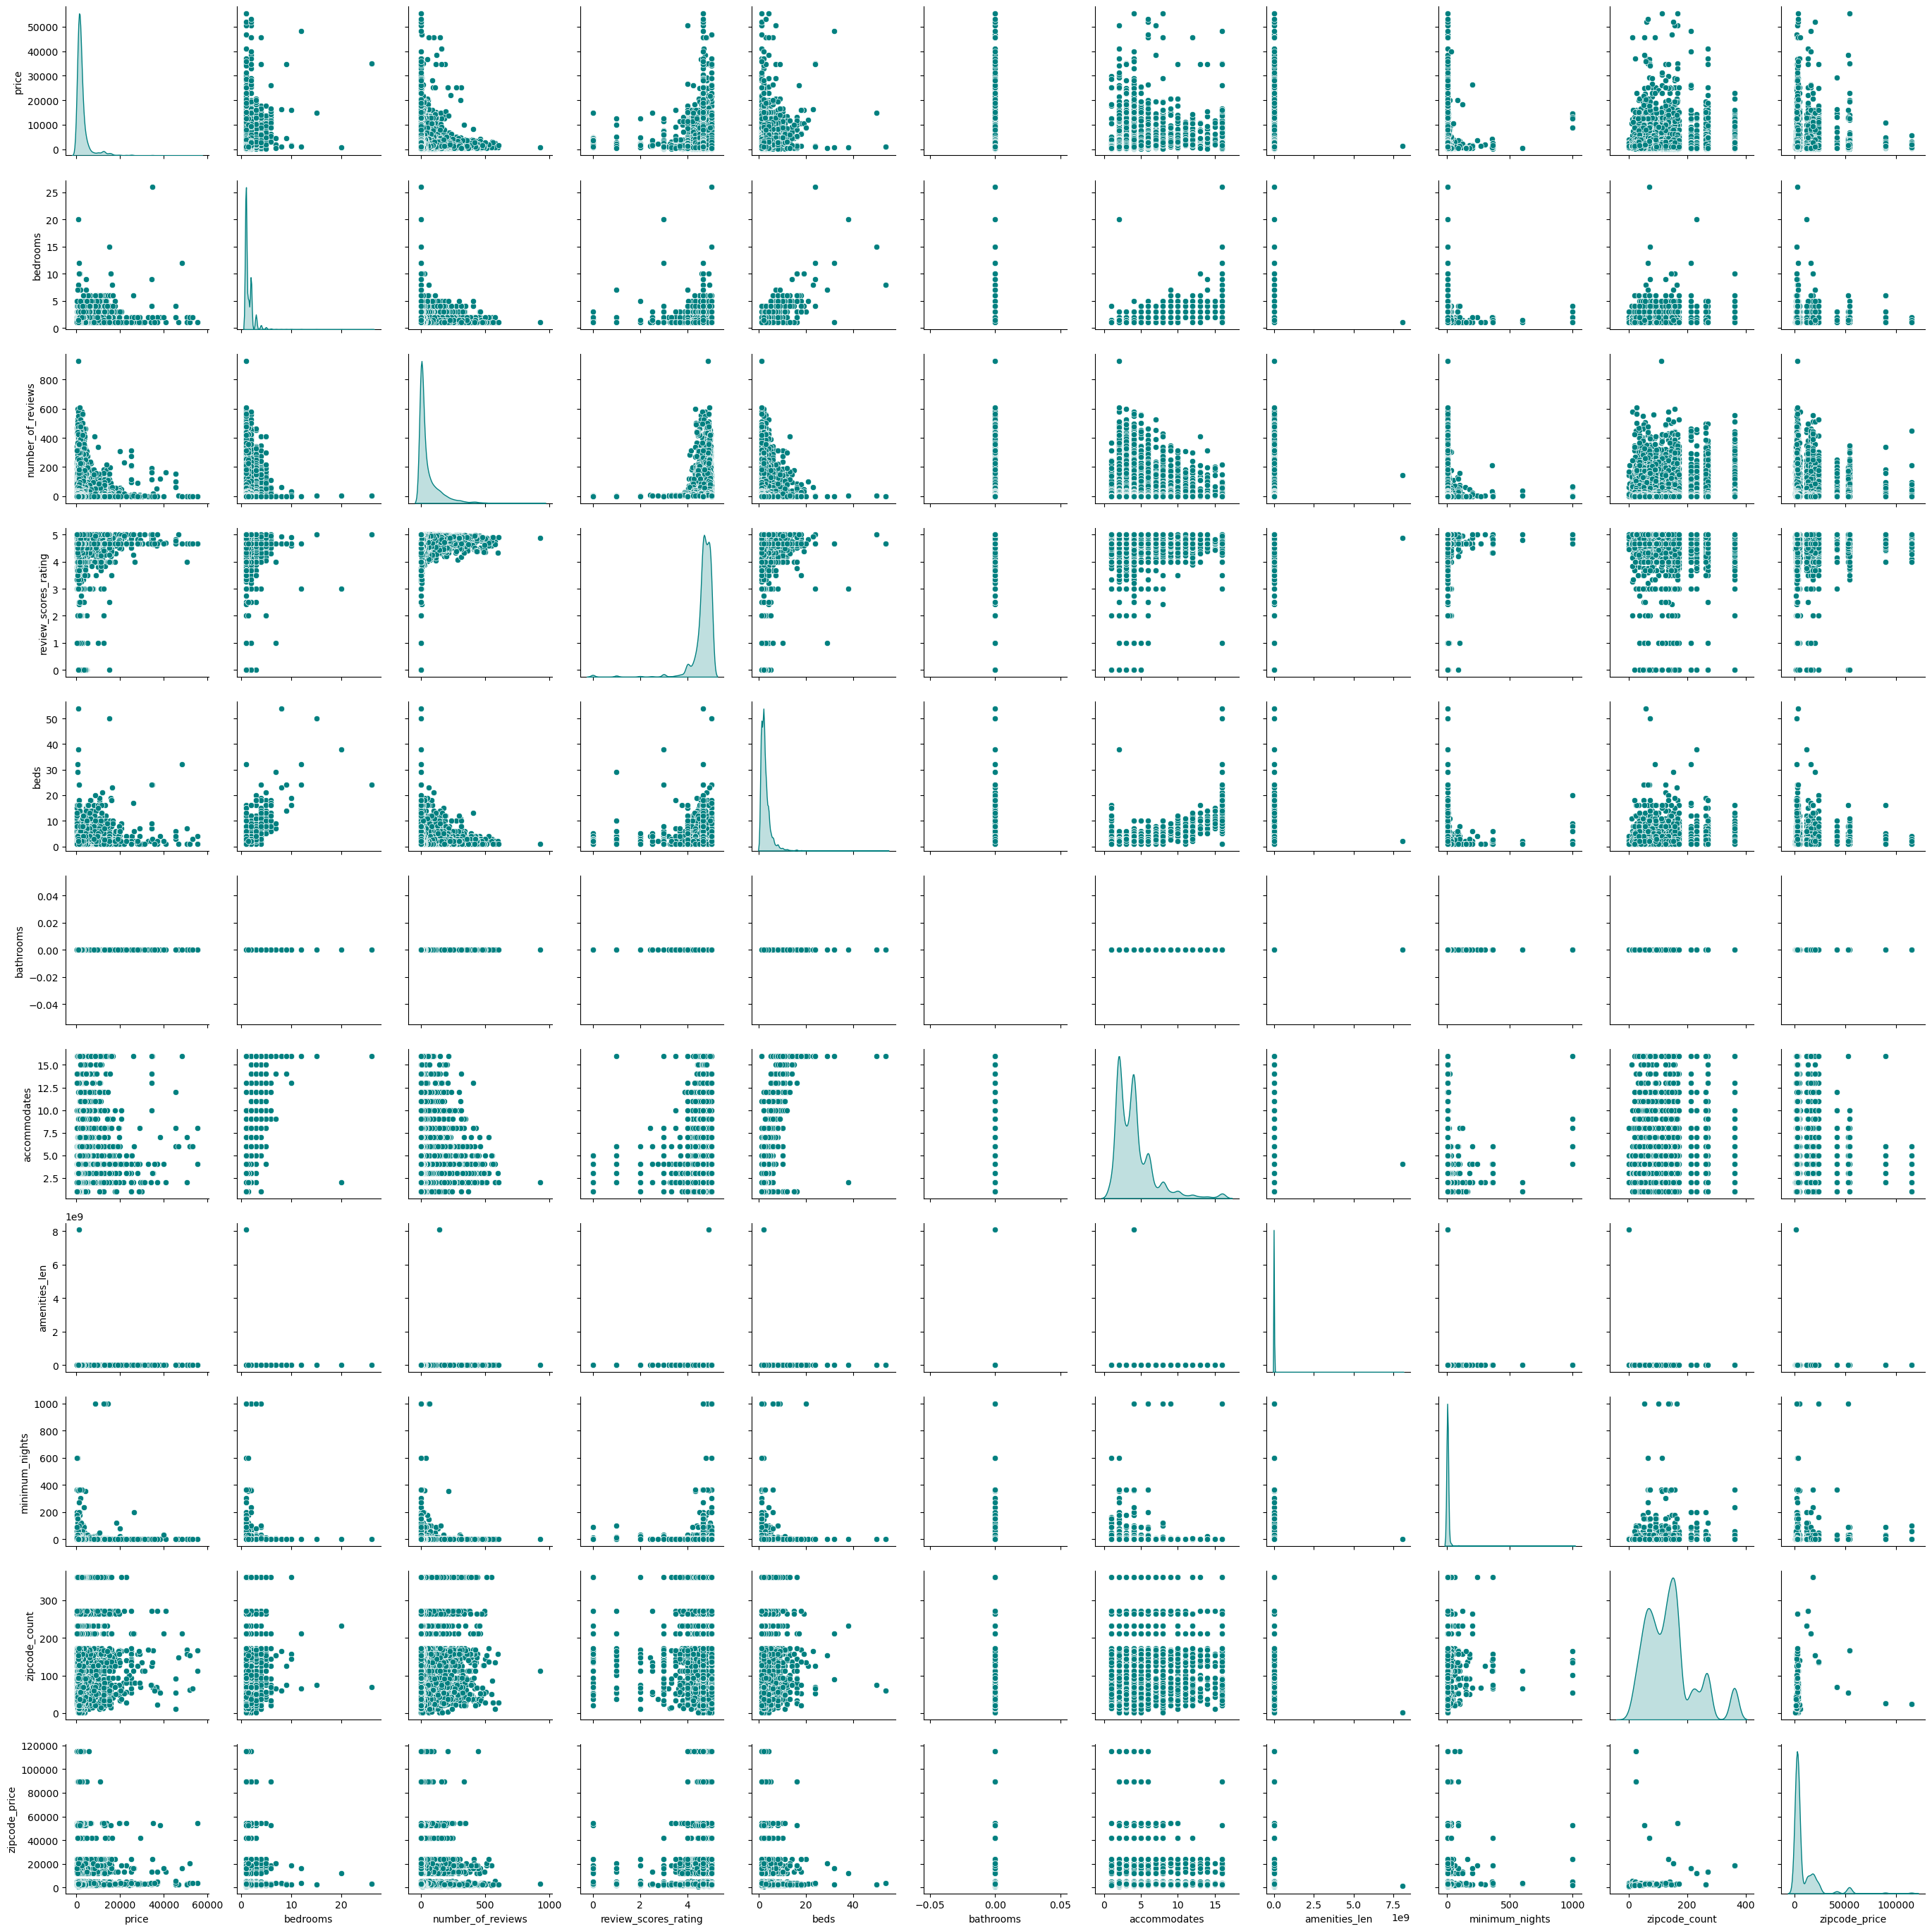

<Figure size 640x480 with 0 Axes>

In [148]:
sns.pairplot(data_prague[cols], height=2.5, diag_kind='kde')
plt.tight_layout()
plt.savefig('prague_matrix_pair_plot.png', dpi=300)

plt.show()
plt.clf() # Clean parirplot figure from sns

              price     bedrooms  number_of_reviews  review_scores_rating  \
count   6752.000000  6752.000000        6752.000000           6752.000000   
mean    2913.457050     1.502938          55.090344              4.662432   
std     4320.014135     0.923147          85.266012              0.499920   
min      227.000000     1.000000           0.000000              0.000000   
25%     1114.750000     1.000000           2.000000              4.630000   
50%     1704.000000     1.000000          17.000000              4.740000   
75%     2750.250000     2.000000          72.000000              4.910000   
max    55530.000000    26.000000         928.000000              5.000000   

              beds  bathrooms  accommodates  amenities_len  minimum_nights  \
count  6752.000000     6752.0   6752.000000   6.752000e+03     6752.000000   
mean      2.714438        0.0      4.053466   1.275143e+06        5.479858   
std       2.468221        0.0      2.584943   9.833087e+07       40.4089

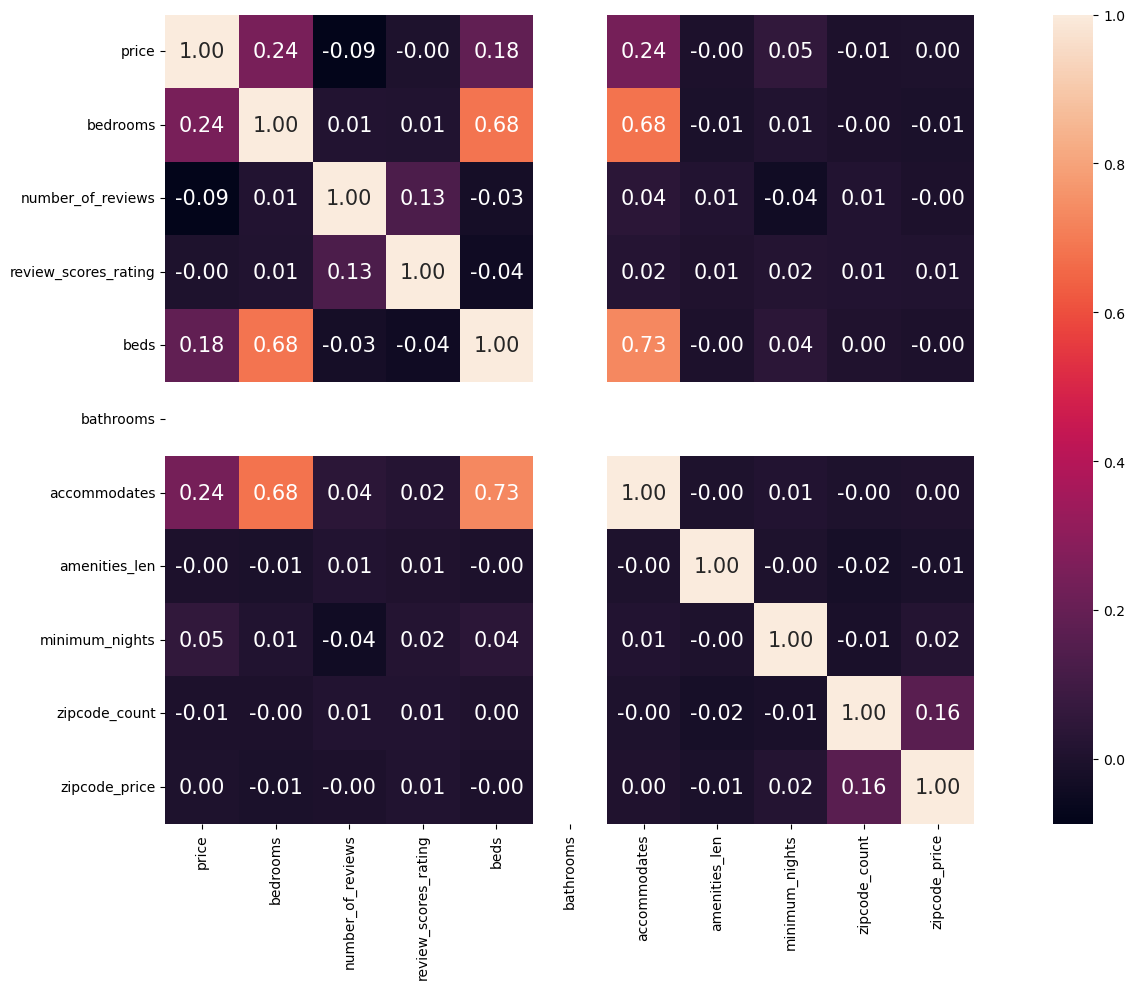

In [149]:
# Preparing data to show in heatmap
print(data_prague[cols].describe())
print(data_prague[cols].info())
data_prague[cols].values.T
print(cols)
print(data_prague[cols].info())
cols_for_heatmap = cols.copy()
cols_for_heatmap.remove('host_is_superhost')

cm = np.corrcoef(data_prague[cols_for_heatmap].values.T)
plt.figure(figsize = (16,10))

hm = sns.heatmap(cm,
                 cbar=True,
                 annot=True,
                 square=True,
                 fmt='.2f',
                 annot_kws={'size': 15},
                 yticklabels=cols_for_heatmap,
                 xticklabels=cols_for_heatmap)

plt.tight_layout()
plt.savefig('praga_heatmap.png', dpi=300)
plt.show()

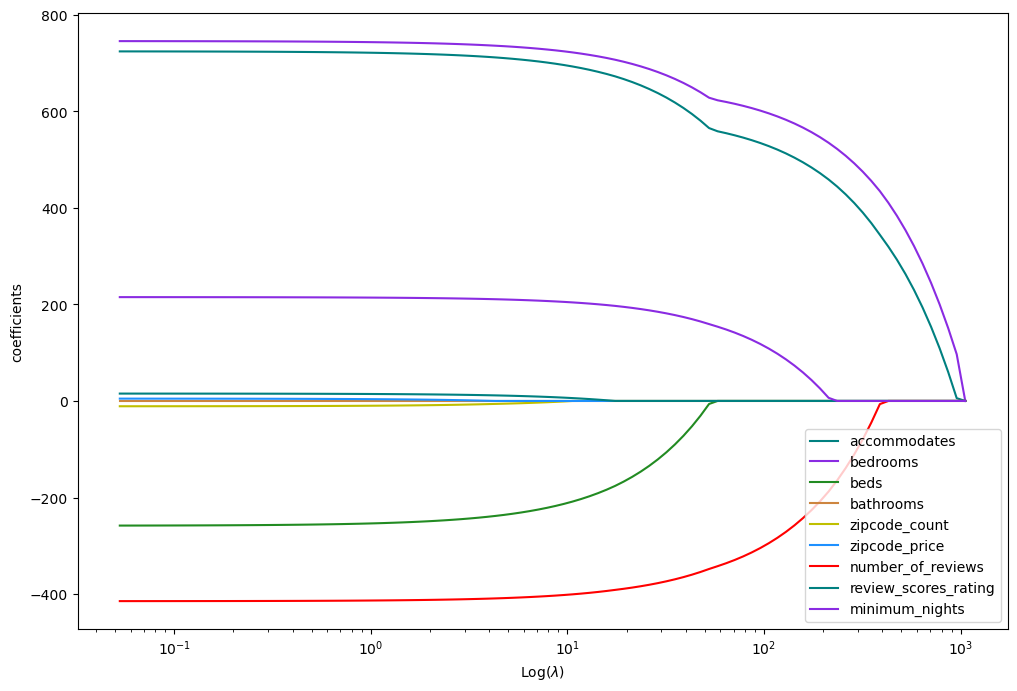

In [151]:
variables = ['accommodates','bedrooms','beds','bathrooms','zipcode_count','zipcode_price','number_of_reviews','review_scores_rating', 'minimum_nights']


data_subset = data_prague.loc[:, variables + ['price']]
data_subset.dropna(inplace=True)

X = data_subset.loc[:,variables]
X = preprocessing.scale(X)
y = np.array(data_subset.price)

alphas_lasso, coefs_lasso, _ = linear_model.lasso_path(X, y, eps=5e-5)

# Display results
plt.figure(figsize = (12,8))

for i in range(X.shape[1]):
    plt.plot(alphas_lasso, coefs_lasso[i], label = variables[i])

plt.xscale('log')
plt.xlabel('Log($\\lambda$)')
plt.ylabel('coefficients')
#plt.title('Lasso paths - Sklearn')
plt.legend()
plt.axis('tight')

plt.savefig('praga_lasso.png', dpi=300)